# Examining the BERT-Base Uncased Model

## 1. Applying 5-Fold Cross Validation

In [5]:
# Import packages
import torch
import numpy as np
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from simpletransformers.classification import ClassificationModel
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [61]:
# Read the files
df_top_1000 = pd.read_csv("./data/top_1000_tags.csv")
df_annotations = pd.read_csv("./data/df_unique.csv")

### 1.1 Character-Perspective Category

In [ ]:
train_data = df_top_1000[["Tag", "Character"]].copy()

# Encode the Character column as numbers
le_char = preprocessing.LabelEncoder()
train_data["labels"] = le_char.fit_transform(train_data["Character"])

train_data = train_data.rename(columns={"Tag": "text",}) # Rename the column

train_data = train_data[["text", "labels"]]

In [22]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Prepare 5-fold cross validation

results = {
    "accuracy": [],
    "precision_macro": [],
    "precision_weighted": [],
    "recall_macro": [],
    "recall_weighted": [],
    "f1_macro": [],
    "f1_weighted": []
}

all_true = []
all_pred = []

for fold, (train_index, val_index) in enumerate(kf.split(train_data["text"], train_data["labels"]), start=1):
    print(f"\nFold {fold}")
    # Splitting Dataframe
    train_df = train_data.iloc[train_index].copy()
    val_df = train_data.iloc[val_index].copy()

    # Defining the model
    model = ClassificationModel(
        'bert',
        'bert-base-uncased',
        num_labels=6,
        use_cuda=True,
        args={
            "num_train_epochs": 5,
            "train_batch_size": 16,
            "eval_batch_size": 16,
            "overwrite_output_dir": True,
            "reprocess_input_data": True,
            "save_eval_checkpoints": False,
            "save_model_every_epoch": False
        }
    )

    model.train_model(train_df) # Train the model

    # Validate the model
    result, model_outputs, wrong_predictions = model.eval_model(val_df, acc=accuracy_score)

    predictions = np.argmax(model_outputs, axis=1) # Get predictions
    true_labels = val_df["labels"].to_numpy() # Get true labels

    all_true.extend(true_labels)
    all_pred.extend(predictions)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predictions)

    precision_macro = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    precision_weighted = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall_macro = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    recall_weighted = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1_macro = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    f1_weighted = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store results
    results["accuracy"].append(accuracy)
    results["precision_macro"].append(precision_macro)
    results["precision_weighted"].append(precision_weighted)
    results["recall_macro"].append(recall_macro)
    results["recall_weighted"].append(recall_weighted)
    results["f1_macro"].append(f1_macro)
    results["f1_weighted"].append(f1_weighted)

    # Print confusion matrix
    cm = confusion_matrix(true_labels, predictions)
    print(cm)
    # Print scores for this fold
    print("Accuracy:", accuracy)
    print("Precision Macro:", precision_macro)
    print("Precision Weighted:", precision_weighted)
    print("Recall Macro:", recall_macro)
    print("Recall Weighted:", recall_weighted)
    print("F1 Macro:", f1_macro)
    print("F1 Weighted:", f1_weighted)
    print("\nClassification Report:")
    print(classification_report(
            true_labels,
            predictions,
            target_names=le_char.classes_,
            zero_division=0
        )
    )


Fold 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


... (71 outputs left out)

0it [00:00, ?it/s]

Running Evaluation:   0%|          | 0/13 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:1570: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


[[14  0  4  0  0  3]
 [ 0 25  4  0  0  1]
 [ 5  2 85  0  0  3]
 [ 0  2  1  0  0  1]
 [ 1  1  4  0  4  1]
 [ 0  2  4  1  0 32]]
Accuracy: 0.8
Precision Macro: 0.6825118563685636
Precision Weighted: 0.7937159552845529
Recall Macro: 0.5964810043757413
Recall Weighted: 0.8
F1 Macro: 0.6142759896569
F1 Weighted: 0.7879068694993484

Classification Report:
                      precision    recall  f1-score   support

           Biography       0.70      0.67      0.68        21
Emotion/Mental State       0.78      0.83      0.81        30
        No Character       0.83      0.89      0.86        95
         Personality       0.00      0.00      0.00         4
    Physical Feature       1.00      0.36      0.53        11
        Relationship       0.78      0.82      0.80        39

            accuracy                           0.80       200
           macro avg       0.68      0.60      0.61       200
        weighted avg       0.79      0.80      0.79       200



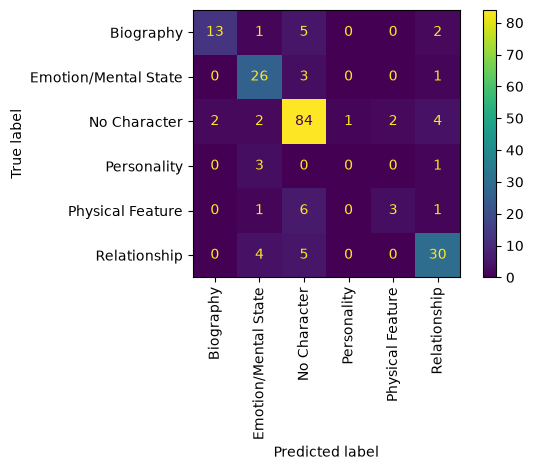


Overall 5-Fold Classification Report:
                      precision    recall  f1-score   support

           Biography       0.68      0.75      0.71       106
Emotion/Mental State       0.74      0.76      0.75       152
        No Character       0.82      0.83      0.83       475
         Personality       0.00      0.00      0.00        17
    Physical Feature       0.53      0.56      0.55        55
        Relationship       0.78      0.75      0.77       195

            accuracy                           0.77      1000
           macro avg       0.59      0.61      0.60      1000
        weighted avg       0.76      0.77      0.76      1000



{'Accuracy Mean': np.float64(0.7690000000000001),
 'Accuracy SD': np.float64(0.023558437978779514),
 'Precision Macro Mean': np.float64(0.601527015103828),
 'Precision Macro SD': np.float64(0.02667484214738941),
 'Precision Weighted Mean': np.float64(0.7627859428287869),
 'Precision Weighted SD': np.float64(0.015943192760560134),
 'Recall Macro Mean': np.float64(0.6098655899844354),
 'Recall Macro SD': np.float64(0.03046208050128698),
 'Recall Weighted Mean': np.float64(0.7690000000000001),
 'Recall Weighted SD': np.float64(0.023558437978779514),
 'F1 Macro Mean': np.float64(0.6002429381432786),
 'F1 Macro SD': np.float64(0.024881651633064477),
 'F1 Weighted Mean': np.float64(0.7630460867612749),
 'F1 Weighted SD': np.float64(0.020269076175718933)}

In [ ]:
cm = confusion_matrix(true_labels, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_char.classes_
)

disp.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report across all 5 folds
print("\nOverall 5-Fold Classification Report:")
print(
    classification_report(
        all_true,
        all_pred,
        target_names=le_char.classes_,
        zero_division=0
    )
)

bert_results = {
    "Accuracy Mean": np.mean(results["accuracy"]),
    "Accuracy SD": np.std(results["accuracy"], ddof=1),
    "Precision Macro Mean": np.mean(results["precision_macro"]),
    "Precision Macro SD": np.std(results["precision_macro"], ddof=1),
    "Precision Weighted Mean": np.mean(results["precision_weighted"]),
    "Precision Weighted SD": np.std(results["precision_weighted"], ddof=1),
    "Recall Macro Mean": np.mean(results["recall_macro"]),
    "Recall Macro SD": np.std(results["recall_macro"], ddof=1),
    "Recall Weighted Mean": np.mean(results["recall_weighted"]),
    "Recall Weighted SD": np.std(results["recall_weighted"], ddof=1),
    "F1 Macro Mean": np.mean(results["f1_macro"]),
    "F1 Macro SD": np.std(results["f1_macro"], ddof=1),
    "F1 Weighted Mean": np.mean(results["f1_weighted"]),
    "F1 Weighted SD": np.std(results["f1_weighted"], ddof=1)
}

bert_results

### 1.2 Narrative-Perspective Category

In [24]:
train_data = df_top_1000[["Tag", "Narrative"]].copy()

# Encode the Narrative column as numbers
le_nar = preprocessing.LabelEncoder()
train_data["labels"] = le_nar.fit_transform(train_data["Narrative"])

train_data = train_data.rename(columns={"Tag": "text",}) # Rename the column

train_data = train_data[["text", "labels"]]

In [32]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Prepare 5-fold cross validation

results = {
    "accuracy": [],
    "precision_macro": [],
    "precision_weighted": [],
    "recall_macro": [],
    "recall_weighted": [],
    "f1_macro": [],
    "f1_weighted": []
}

all_true = []
all_pred = []

for fold, (train_index, val_index) in enumerate(kf.split(train_data["text"], train_data["labels"]), start=1):
    print(f"\nFold {fold}")
    # Splitting Dataframe
    train_df = train_data.iloc[train_index].copy()
    val_df = train_data.iloc[val_index].copy()

    # Defining the model
    model = ClassificationModel(
        'bert',
        'bert-base-uncased',
        num_labels=7,
        use_cuda=True,
        args={
            "num_train_epochs": 7,
            "train_batch_size": 16,
            "eval_batch_size": 16,
            "overwrite_output_dir": True,
            "reprocess_input_data": True,
            "save_eval_checkpoints": False,
            "save_model_every_epoch": False
        }
    )

    model.train_model(train_df) # Train the model

    # Validate the model
    result, model_outputs, wrong_predictions = model.eval_model(val_df, acc=accuracy_score)

    predictions = np.argmax(model_outputs, axis=1) # Get predictions
    true_labels = val_df["labels"].to_numpy() # Get true labels

    all_true.extend(true_labels)
    all_pred.extend(predictions)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predictions)

    precision_macro = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    precision_weighted = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall_macro = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    recall_weighted = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1_macro = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    f1_weighted = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store results
    results["accuracy"].append(accuracy)
    results["precision_macro"].append(precision_macro)
    results["precision_weighted"].append(precision_weighted)
    results["recall_macro"].append(recall_macro)
    results["recall_weighted"].append(recall_weighted)
    results["f1_macro"].append(f1_macro)
    results["f1_weighted"].append(f1_weighted)

    # Print confusion matrix
    cm = confusion_matrix(true_labels, predictions)
    print(cm)
    # Print scores for this fold
    print("Accuracy:", accuracy)
    print("Precision Macro:", precision_macro)
    print("Precision Weighted:", precision_weighted)
    print("Recall Macro:", recall_macro)
    print("Recall Weighted:", recall_weighted)
    print("F1 Macro:", f1_macro)
    print("F1 Weighted:", f1_weighted)
    print("\nClassification Report:")
    print(classification_report(
            true_labels,
            predictions,
            target_names=le_nar.classes_,
            zero_division=0
        )
    )


Fold 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


... (81 outputs left out)

0it [00:00, ?it/s]

Running Evaluation:   0%|          | 0/13 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:1570: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


[[56  0  0  5  4  4  1]
 [ 0  4  0  2  1  2  0]
 [ 0  3  0  1  0  1  0]
 [ 3  1  0 37  1  2  1]
 [ 5  0  0  1 10  2  1]
 [ 3  0  0  4  0 24  1]
 [ 2  1  0  0  1  0 16]]
Accuracy: 0.735
Precision Macro: 0.5814268895964183
Precision Weighted: 0.7161546096699548
Recall Macro: 0.5918546365914786
Recall Weighted: 0.735
F1 Macro: 0.5858743820788953
F1 Weighted: 0.724682189833365

Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.81      0.80      0.81        70
              Format       0.44      0.44      0.44         9
   Narrative Methods       0.00      0.00      0.00         5
        No Narrative       0.74      0.82      0.78        45
                Plot       0.59      0.53      0.56        19
         Theme/Genre       0.69      0.75      0.72        32
        WorldSetting       0.80      0.80      0.80        20

            accuracy                           0.73       200
           macro avg       0.58      0.5

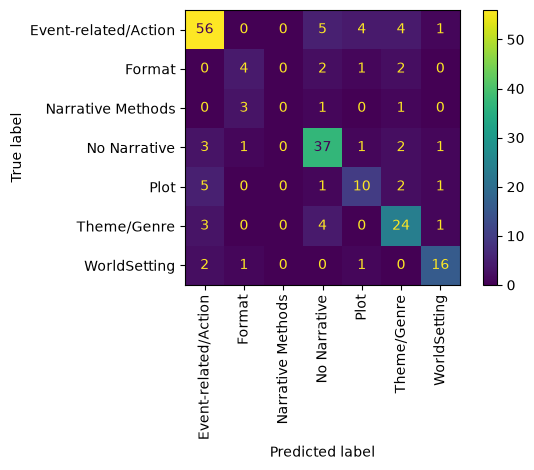


Overall 5-Fold Classification Report:
                      precision    recall  f1-score   support

Event-related/Action       0.80      0.83      0.82       351
              Format       0.65      0.58      0.61        45
   Narrative Methods       0.75      0.26      0.39        23
        No Narrative       0.68      0.67      0.68       224
                Plot       0.53      0.47      0.50        94
         Theme/Genre       0.61      0.71      0.66       163
        WorldSetting       0.79      0.75      0.77       100

            accuracy                           0.71      1000
           macro avg       0.69      0.61      0.63      1000
        weighted avg       0.71      0.71      0.71      1000



{'Accuracy Mean': np.float64(0.7110000000000001),
 'Accuracy SD': np.float64(0.041743262929483584),
 'Precision Macro Mean': np.float64(0.678341748210849),
 'Precision Macro SD': np.float64(0.08714719778064516),
 'Precision Weighted Mean': np.float64(0.7110600018922552),
 'Precision Weighted SD': np.float64(0.043768806467556105),
 'Recall Macro Mean': np.float64(0.6119741722530827),
 'Recall Macro SD': np.float64(0.06570087445126192),
 'Recall Weighted Mean': np.float64(0.7110000000000001),
 'Recall Weighted SD': np.float64(0.041743262929483584),
 'F1 Macro Mean': np.float64(0.6286232887621674),
 'F1 Macro SD': np.float64(0.0727662676750791),
 'F1 Weighted Mean': np.float64(0.7061095408678918),
 'F1 Weighted SD': np.float64(0.04408606061641354)}

In [33]:
cm = confusion_matrix(true_labels, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_nar.classes_
)

disp.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report across all 5 folds
print("\nOverall 5-Fold Classification Report:")
print(
    classification_report(
        all_true,
        all_pred,
        target_names=le_nar.classes_,
        zero_division=0
    )
)

bert_results = {
    "Accuracy Mean": np.mean(results["accuracy"]),
    "Accuracy SD": np.std(results["accuracy"], ddof=1),
    "Precision Macro Mean": np.mean(results["precision_macro"]),
    "Precision Macro SD": np.std(results["precision_macro"], ddof=1),
    "Precision Weighted Mean": np.mean(results["precision_weighted"]),
    "Precision Weighted SD": np.std(results["precision_weighted"], ddof=1),
    "Recall Macro Mean": np.mean(results["recall_macro"]),
    "Recall Macro SD": np.std(results["recall_macro"], ddof=1),
    "Recall Weighted Mean": np.mean(results["recall_weighted"]),
    "Recall Weighted SD": np.std(results["recall_weighted"], ddof=1),
    "F1 Macro Mean": np.mean(results["f1_macro"]), 
    "F1 Macro SD": np.std(results["f1_macro"], ddof=1),
    "F1 Weighted Mean": np.mean(results["f1_weighted"]),
    "F1 Weighted SD": np.std(results["f1_weighted"], ddof=1)
}

bert_results

### 1.3 Content-Control Porn

In [36]:
train_data = df_top_1000[["Tag", "Porn"]].copy()

# Encode the Porn column as numbers
le_porn = preprocessing.LabelEncoder()
train_data["labels"] = le_porn.fit_transform(train_data["Porn"])

train_data = train_data.rename(columns={"Tag": "text",}) # Rename the column

train_data = train_data[["text", "labels"]]

In [39]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Prepare 5-fold cross validation

results = {
    "accuracy": [],
    "precision_macro": [],
    "precision_weighted": [],
    "recall_macro": [],
    "recall_weighted": [],
    "f1_macro": [],
    "f1_weighted": []
}

all_true = []
all_pred = []

for fold, (train_index, val_index) in enumerate(kf.split(train_data["text"], train_data["labels"]), start=1):
    print(f"\nFold {fold}")
    # Splitting Dataframe
    train_df = train_data.iloc[train_index].copy()
    val_df = train_data.iloc[val_index].copy()

    # Defining the model
    model = ClassificationModel(
        'bert',
        'bert-base-uncased',
        num_labels=2,
        use_cuda=True,
        args={
            "num_train_epochs": 7,
            "train_batch_size": 16,
            "eval_batch_size": 16,
            "overwrite_output_dir": True,
            "reprocess_input_data": True,
            "save_eval_checkpoints": False,
            "save_model_every_epoch": False
        }
    )

    model.train_model(train_df) # Train the model

    # Validate the model
    result, model_outputs, wrong_predictions = model.eval_model(val_df, acc=accuracy_score)

    predictions = np.argmax(model_outputs, axis=1) # Get predictions
    true_labels = val_df["labels"].to_numpy() # Get true labels

    all_true.extend(true_labels)
    all_pred.extend(predictions)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predictions)

    precision_macro = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    precision_weighted = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall_macro = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    recall_weighted = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1_macro = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    f1_weighted = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store results
    results["accuracy"].append(accuracy)
    results["precision_macro"].append(precision_macro)
    results["precision_weighted"].append(precision_weighted)
    results["recall_macro"].append(recall_macro)
    results["recall_weighted"].append(recall_weighted)
    results["f1_macro"].append(f1_macro)
    results["f1_weighted"].append(f1_weighted)

    # Print confusion matrix
    cm = confusion_matrix(true_labels, predictions)
    print(cm)
    # Print scores for this fold
    print("Accuracy:", accuracy)
    print("Precision Macro:", precision_macro)
    print("Precision Weighted:", precision_weighted)
    print("Recall Macro:", recall_macro)
    print("Recall Weighted:", recall_weighted)
    print("F1 Macro:", f1_macro)
    print("F1 Weighted:", f1_weighted)
    print("\nClassification Report:")
    print(classification_report(
            true_labels,
            predictions,
            target_names=le_porn.classes_,
            zero_division=0
        )
    )


Fold 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


... (81 outputs left out)

0it [00:00, ?it/s]

Running Evaluation:   0%|          | 0/13 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:1570: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


[[ 21   8]
 [  4 167]]
Accuracy: 0.94
Precision Macro: 0.8971428571428571
Precision Weighted: 0.9377142857142857
Recall Macro: 0.8503730590844929
Recall Weighted: 0.94
F1 Macro: 0.8715478484264612
F1 Weighted: 0.9381245985870262

Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.84      0.72      0.78        29
    Not Porn       0.95      0.98      0.97       171

    accuracy                           0.94       200
   macro avg       0.90      0.85      0.87       200
weighted avg       0.94      0.94      0.94       200



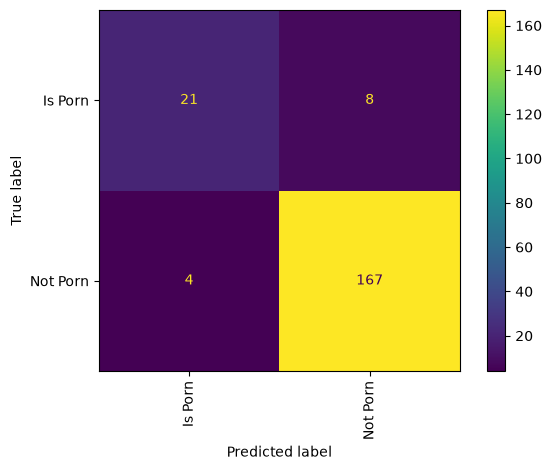


Overall 5-Fold Classification Report:
              precision    recall  f1-score   support

     Is Porn       0.82      0.71      0.76       143
    Not Porn       0.95      0.97      0.96       857

    accuracy                           0.94      1000
   macro avg       0.89      0.84      0.86      1000
weighted avg       0.93      0.94      0.94      1000



{'Accuracy Mean': np.float64(0.937),
 'Accuracy SD': np.float64(0.013038404810405262),
 'Precision Macro Mean': np.float64(0.8892562844245108),
 'Precision Macro SD': np.float64(0.036929013449588),
 'Precision Weighted Mean': np.float64(0.93501621153321),
 'Precision Weighted SD': np.float64(0.012754719323779659),
 'Recall Macro Mean': np.float64(0.8437023961936383),
 'Recall Macro SD': np.float64(0.019951156970123007),
 'Recall Weighted Mean': np.float64(0.937),
 'Recall Weighted SD': np.float64(0.013038404810405262),
 'F1 Macro Mean': np.float64(0.86401385273741),
 'F1 Macro SD': np.float64(0.026377079627171892),
 'F1 Weighted Mean': np.float64(0.9352010126811141),
 'F1 Weighted SD': np.float64(0.012549622134022938)}

In [40]:
cm = confusion_matrix(true_labels, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_porn.classes_
)

disp.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report across all 5 folds
print("\nOverall 5-Fold Classification Report:")
print(
    classification_report(
        all_true,
        all_pred,
        target_names=le_porn.classes_,
        zero_division=0
    )
)

bert_results = {
    "Accuracy Mean": np.mean(results["accuracy"]),
    "Accuracy SD": np.std(results["accuracy"], ddof=1),
    "Precision Macro Mean": np.mean(results["precision_macro"]),
    "Precision Macro SD": np.std(results["precision_macro"], ddof=1),
    "Precision Weighted Mean": np.mean(results["precision_weighted"]),
    "Precision Weighted SD": np.std(results["precision_weighted"], ddof=1),
    "Recall Macro Mean": np.mean(results["recall_macro"]),
    "Recall Macro SD": np.std(results["recall_macro"], ddof=1),
    "Recall Weighted Mean": np.mean(results["recall_weighted"]),
    "Recall Weighted SD": np.std(results["recall_weighted"], ddof=1),
    "F1 Macro Mean": np.mean(results["f1_macro"]), 
    "F1 Macro SD": np.std(results["f1_macro"], ddof=1),
    "F1 Weighted Mean": np.mean(results["f1_weighted"]),
    "F1 Weighted SD": np.std(results["f1_weighted"], ddof=1)
}

bert_results

### 1.4 Content-Control Kink

In [41]:
train_data = df_top_1000[["Tag", "Kink"]].copy()

# Encode the Kink column as numbers
le_kink = preprocessing.LabelEncoder()
train_data["labels"] = le_kink.fit_transform(train_data["Kink"])

train_data = train_data.rename(columns={"Tag": "text",}) # Rename the column

train_data = train_data[["text", "labels"]]

In [48]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Prepare 5-fold cross validation

results = {
    "accuracy": [],
    "precision_macro": [],
    "precision_weighted": [],
    "recall_macro": [],
    "recall_weighted": [],
    "f1_macro": [],
    "f1_weighted": []
}

all_true = []
all_pred = []

for fold, (train_index, val_index) in enumerate(kf.split(train_data["text"], train_data["labels"]), start=1):
    print(f"\nFold {fold}")
    # Splitting Dataframe
    train_df = train_data.iloc[train_index].copy()
    val_df = train_data.iloc[val_index].copy()

    # Defining the model
    model = ClassificationModel(
        'bert',
        'bert-base-uncased',
        num_labels=2,
        use_cuda=True,
        args={
            "num_train_epochs": 7,
            "train_batch_size": 16,
            "eval_batch_size": 16,
            "overwrite_output_dir": True,
            "reprocess_input_data": True,
            "save_eval_checkpoints": False,
            "save_model_every_epoch": False
        }
    )

    model.train_model(train_df) # Train the model

    # Validate the model
    result, model_outputs, wrong_predictions = model.eval_model(val_df, acc=accuracy_score)

    predictions = np.argmax(model_outputs, axis=1) # Get predictions
    true_labels = val_df["labels"].to_numpy() # Get true labels

    all_true.extend(true_labels)
    all_pred.extend(predictions)

    # Calculate metrics
    accuracy = accuracy_score(true_labels, predictions)

    precision_macro = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    precision_weighted = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    recall_macro = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    recall_weighted = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )
    f1_macro = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )
    f1_weighted = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store results
    results["accuracy"].append(accuracy)
    results["precision_macro"].append(precision_macro)
    results["precision_weighted"].append(precision_weighted)
    results["recall_macro"].append(recall_macro)
    results["recall_weighted"].append(recall_weighted)
    results["f1_macro"].append(f1_macro)
    results["f1_weighted"].append(f1_weighted)

    # Print confusion matrix
    cm = confusion_matrix(true_labels, predictions)
    print(cm)
    # Print scores for this fold
    print("Accuracy:", accuracy)
    print("Precision Macro:", precision_macro)
    print("Precision Weighted:", precision_weighted)
    print("Recall Macro:", recall_macro)
    print("Recall Weighted:", recall_weighted)
    print("F1 Macro:", f1_macro)
    print("F1 Weighted:", f1_weighted)
    print("\nClassification Report:")
    print(classification_report(
            true_labels,
            predictions,
            target_names=le_kink.classes_,
            zero_division=0
        )
    )


Fold 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/1 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


... (81 outputs left out)

0it [00:00, ?it/s]

Running Evaluation:   0%|          | 0/13 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:1570: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


[[  6  11]
 [  4 179]]
Accuracy: 0.925
Precision Macro: 0.7710526315789474
Precision Weighted: 0.9130263157894737
Recall Macro: 0.6655416264866603
Recall Weighted: 0.925
F1 Macro: 0.7021149836163241
F1 Weighted: 0.9159815311289842

Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.60      0.35      0.44        17
    Not Kink       0.94      0.98      0.96       183

    accuracy                           0.93       200
   macro avg       0.77      0.67      0.70       200
weighted avg       0.91      0.93      0.92       200



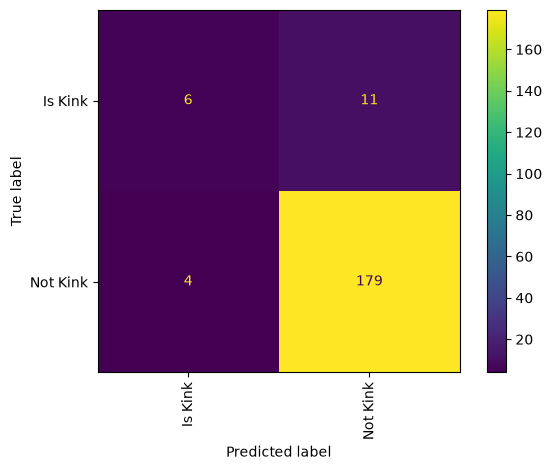


Overall 5-Fold Classification Report:
              precision    recall  f1-score   support

     Is Kink       0.60      0.40      0.48        83
    Not Kink       0.95      0.98      0.96       917

    accuracy                           0.93      1000
   macro avg       0.77      0.69      0.72      1000
weighted avg       0.92      0.93      0.92      1000



{'Accuracy Mean': np.float64(0.9280000000000002),
 'Accuracy SD': np.float64(0.008366600265340763),
 'Precision Macro Mean': np.float64(0.7818662361993844),
 'Precision Macro SD': np.float64(0.05566514722866116),
 'Precision Weighted Mean': np.float64(0.9199132310508619),
 'Precision Weighted SD': np.float64(0.008906261616389511),
 'Recall Macro Mean': np.float64(0.6872814557041634),
 'Recall Macro SD': np.float64(0.02895510224773943),
 'Recall Weighted Mean': np.float64(0.9280000000000002),
 'Recall Weighted SD': np.float64(0.008366600265340763),
 'F1 Macro Mean': np.float64(0.7196695768685505),
 'F1 Macro SD': np.float64(0.02678665699749812),
 'F1 Weighted Mean': np.float64(0.9212096989348032),
 'F1 Weighted SD': np.float64(0.0074289402769748296)}

In [50]:
cm = confusion_matrix(true_labels, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_kink.classes_
)

disp.plot(xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report across all 5 folds
print("\nOverall 5-Fold Classification Report:")
print(
    classification_report(
        all_true,
        all_pred,
        target_names=le_kink.classes_,
        zero_division=0
    )
)

bert_results = {
    "Accuracy Mean": np.mean(results["accuracy"]),
    "Accuracy SD": np.std(results["accuracy"], ddof=1),
    "Precision Macro Mean": np.mean(results["precision_macro"]),
    "Precision Macro SD": np.std(results["precision_macro"], ddof=1),
    "Precision Weighted Mean": np.mean(results["precision_weighted"]),
    "Precision Weighted SD": np.std(results["precision_weighted"], ddof=1),
    "Recall Macro Mean": np.mean(results["recall_macro"]),
    "Recall Macro SD": np.std(results["recall_macro"], ddof=1),
    "Recall Weighted Mean": np.mean(results["recall_weighted"]),
    "Recall Weighted SD": np.std(results["recall_weighted"], ddof=1),
    "F1 Macro Mean": np.mean(results["f1_macro"]), 
    "F1 Macro SD": np.std(results["f1_macro"], ddof=1),
    "F1 Weighted Mean": np.mean(results["f1_weighted"]),
    "F1 Weighted SD": np.std(results["f1_weighted"], ddof=1)
}

bert_results

## 2. Annotating the Additional Tags

### 2.1 Character-Perspective Category Annotation

In [52]:
le_char = preprocessing.LabelEncoder() # Preprocess the Label Encoder
char_train_data = df_top_1000[["Tag", "Character"]].copy() # Copy the dataset
char_train_data["labels"] = le_char.fit_transform(char_train_data["Character"]) # Fit transform the model
char_train_data = char_train_data.rename(columns={"Tag": "text"}) # Rename the column
char_train_data = char_train_data[["text", "labels"]] # Select the columns

In [53]:
char_model = ClassificationModel(
    "bert",
    "bert-base-uncased",
    num_labels=len(le_char.classes_),
    use_cuda=True,
    args={
        "num_train_epochs": 5,
        "train_batch_size": 16,
        "eval_batch_size": 16,
        "overwrite_output_dir": True,
        "reprocess_input_data": True,
        "save_model_every_epoch": False
    }
)

char_model.train_model(char_train_data) # Train the model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/2 [00:00<?, ?it/s]

Epoch:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


Running Epoch 1 of 5:   0%|          | 0/63 [00:00<?, ?it/s]

... (3 outputs left out)

Running Epoch 4 of 5:   0%|          | 0/63 [00:00<?, ?it/s]

Running Epoch 5 of 5:   0%|          | 0/63 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(315, 0.6896744622124567)

In [62]:
predictions, raw_outputs = char_model.predict(df_annotations["Additional Tags"].tolist()) # Annotate the additional tags
df_annotations["Character"] = le_char.inverse_transform(predictions) # Turn the numerical predictions into labels
df_annotations

  0%|          | 0/51 [00:00<?, ?it/s]

Predicting:   0%|          | 0/1620 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:2260: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


,Additional Tags,Character
0,Fluff,No Character
1,Angst,No Character
2,AvaLance,No Character
3,Hurt/Comfort,Emotion/Mental State
4,Angst with a Happy Ending,No Character
...,...,...
25903,Miles Morales is smitten,Relationship
25904,y/n cries,No Character
25905,texting while fighting,No Character
25906,y/n lives off school campus,Relationship


### 2.2 Narrative Perspective Category Annotation

In [63]:
le_nar = preprocessing.LabelEncoder() # Preprocess the Label Encoder
nar_train_data = df_top_1000[["Tag", "Narrative"]].copy() # Copy the dataset
nar_train_data["labels"] = le_nar.fit_transform(nar_train_data["Narrative"]) # Fit transform the model
nar_train_data = nar_train_data.rename(columns={"Tag": "text"}) # Rename the column
nar_train_data = nar_train_data[["text", "labels"]] # Select the columns

In [64]:
nar_model = ClassificationModel(
    "bert",
    "bert-base-uncased",
    num_labels=len(le_nar.classes_),
    use_cuda=True,
    args={
        "num_train_epochs": 7,
        "train_batch_size": 16,
        "eval_batch_size": 16,
        "overwrite_output_dir": True,
        "reprocess_input_data": True,
        "save_model_every_epoch": False
    }
)

nar_model.train_model(nar_train_data) # Train the model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/2 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


Running Epoch 1 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

... (5 outputs left out)

Running Epoch 6 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Running Epoch 7 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(441, 0.6814761183429467)

In [65]:
predictions, raw_outputs = nar_model.predict(df_annotations["Additional Tags"].tolist()) # Annotate the additional tags
df_annotations["Narrative"] = le_nar.inverse_transform(predictions) # Turn the numerical predictions into labels
df_annotations

  0%|          | 0/51 [00:00<?, ?it/s]

Predicting:   0%|          | 0/1620 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:2260: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


,Additional Tags,Character,Narrative
0,Fluff,No Character,Theme/Genre
1,Angst,No Character,Theme/Genre
2,AvaLance,No Character,Plot
3,Hurt/Comfort,Emotion/Mental State,No Narrative
4,Angst with a Happy Ending,No Character,Theme/Genre
...,...,...,...
25903,Miles Morales is smitten,Relationship,No Narrative
25904,y/n cries,No Character,Event-related/Action
25905,texting while fighting,No Character,Event-related/Action
25906,y/n lives off school campus,Relationship,No Narrative


### 2.3 Content-Control Category Porn Label Annotation

In [66]:
le_porn = preprocessing.LabelEncoder() # Preprocess the Label Encoder
porn_train_data = df_top_1000[["Tag", "Porn"]].copy() # Copy the dataset
porn_train_data["labels"] = le_porn.fit_transform(porn_train_data["Porn"]) # Fit transform the model
porn_train_data = porn_train_data.rename(columns={"Tag": "text"}) # Rename the column
porn_train_data = porn_train_data[["text", "labels"]] # Select the columns

In [67]:
porn_model = ClassificationModel(
    "bert",
    "bert-base-uncased",
    num_labels=len(le_porn.classes_),
    use_cuda=True,
    args={
        "num_train_epochs": 7,
        "train_batch_size": 16,
        "eval_batch_size": 16,
        "overwrite_output_dir": True,
        "reprocess_input_data": True,
        "save_model_every_epoch": False
    }
)

porn_model.train_model(porn_train_data) # Train the model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/2 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


Running Epoch 1 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

... (5 outputs left out)

Running Epoch 6 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Running Epoch 7 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(441, 0.10079152975020225)

In [68]:
predictions, raw_outputs = porn_model.predict(df_annotations["Additional Tags"].tolist()) # Annotate the additional tags
df_annotations["Porn"] = le_porn.inverse_transform(predictions) # Turn the numerical predictions into labels
df_annotations

  0%|          | 0/51 [00:00<?, ?it/s]

Predicting:   0%|          | 0/1620 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:2260: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


,Additional Tags,Character,Narrative,Porn
0,Fluff,No Character,Theme/Genre,Not Porn
1,Angst,No Character,Theme/Genre,Not Porn
2,AvaLance,No Character,Plot,Not Porn
3,Hurt/Comfort,Emotion/Mental State,No Narrative,Not Porn
4,Angst with a Happy Ending,No Character,Theme/Genre,Not Porn
...,...,...,...,...
25903,Miles Morales is smitten,Relationship,No Narrative,Not Porn
25904,y/n cries,No Character,Event-related/Action,Not Porn
25905,texting while fighting,No Character,Event-related/Action,Not Porn
25906,y/n lives off school campus,Relationship,No Narrative,Not Porn


### 2.4 Content-Control Category Kink Label Annotation

In [69]:
le_kink = preprocessing.LabelEncoder() # Preprocess the Label Encoder
kink_train_data = df_top_1000[["Tag", "Kink"]].copy() # Copy the dataset
kink_train_data["labels"] = le_kink.fit_transform(kink_train_data["Kink"]) # Fit transform the model
kink_train_data = kink_train_data.rename(columns={"Tag": "text"}) # Rename the column
kink_train_data = kink_train_data[["text", "labels"]] # Select the columns

In [70]:
kink_model = ClassificationModel(
    "bert",
    "bert-base-uncased",
    num_labels=len(le_kink.classes_),
    use_cuda=True,
    args={
        "num_train_epochs": 7,
        "train_batch_size": 16,
        "eval_batch_size": 16,
        "overwrite_output_dir": True,
        "reprocess_input_data": True,
        "save_model_every_epoch": False
    }
)

kink_model.train_model(kink_train_data) # Train the model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  0%|          | 0/2 [00:00<?, ?it/s]

Epoch:   0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:924: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()


Running Epoch 1 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

... (5 outputs left out)

Running Epoch 6 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Running Epoch 7 of 7:   0%|          | 0/63 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(441, 0.10996685601145773)

In [71]:
predictions, raw_outputs = kink_model.predict(df_annotations["Additional Tags"].tolist()) # Annotate the additional tags
df_annotations["Kink"] = le_kink.inverse_transform(predictions) # Turn the numerical predictions into labels
df_annotations

  0%|          | 0/51 [00:00<?, ?it/s]

Predicting:   0%|          | 0/1620 [00:00<?, ?it/s]

c:\Users\camer\anaconda3\envs\ma_dh_thesis\Lib\site-packages\simpletransformers\classification\classification_model.py:2260: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():


,Additional Tags,Character,Narrative,Porn,Kink
0,Fluff,No Character,Theme/Genre,Not Porn,Not Kink
1,Angst,No Character,Theme/Genre,Not Porn,Not Kink
2,AvaLance,No Character,Plot,Not Porn,Not Kink
3,Hurt/Comfort,Emotion/Mental State,No Narrative,Not Porn,Not Kink
4,Angst with a Happy Ending,No Character,Theme/Genre,Not Porn,Not Kink
...,...,...,...,...,...
25903,Miles Morales is smitten,Relationship,No Narrative,Not Porn,Not Kink
25904,y/n cries,No Character,Event-related/Action,Not Porn,Not Kink
25905,texting while fighting,No Character,Event-related/Action,Not Porn,Not Kink
25906,y/n lives off school campus,Relationship,No Narrative,Not Porn,Not Kink


In [73]:
df_annotations.to_csv('./data/df_additional_tag_annotations.csv') # Save the result as a CSV file